# 🔵1) downloads and imports

### 🟠1.1) download stable-diffusion-2-base

In [1]:
# if needed 
#!pip install --upgrade diffusers transformers accelerate scipy safetensors

In [2]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16 
)

# as in the other HW we have done, move it to cuda...
pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sun glasses and mexican hat"

# running the prompt thru the pipe, and getting resaults
image = pipe(prompt).images[0]

#save and disply the image 
image.save("basic_stable_deffusion_check.png")
print("image saved as basic_stable_deffusion_check.png")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

image saved as basic_stable_deffusion_check.png


In [3]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16 
)

# as in the other HW we have done, move it to cuda...
pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sun glasses and mexican hat"

# running the prompt thru the pipe, and getting resaults
image = pipe(prompt).images[0]

#save and disply the image 
image.save("basic_stable_deffusion_check.png")
print("image saved as basic_stable_deffusion_check.png")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

image saved as basic_stable_deffusion_check.png


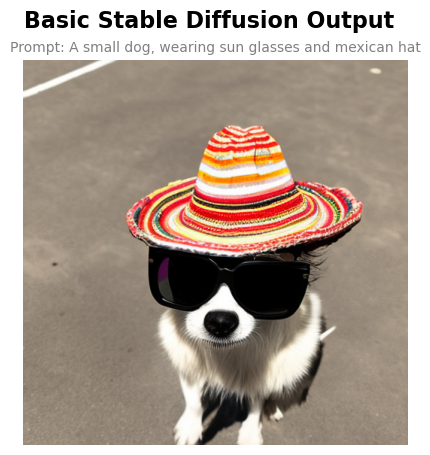

In [4]:
# show image generated
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread("basic_stable_deffusion_check.png")

plt.figure(figsize=(5, 5)) 

plt.imshow(img) 
plt.axis("off") 

plt.suptitle("Basic Stable Diffusion Output", fontsize=16, fontweight='bold')
plt.title("Prompt: A small dog, wearing sun glasses and mexican hat", fontsize=10, color='gray')

plt.show() 

# 🔵2) implementing the base denoising loop from scratch

In [12]:
import torch
import PIL
import numpy as np
from tqdm.auto import tqdm

def get_text_embeddings(pipe, prompt, negative_prompt, device):
    """
    Encodes the prompt and negative prompt into text embeddings.
    """
    text_input = pipe.tokenizer(
        prompt, 
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    text_embeddings = pipe.text_encoder(text_input.input_ids.to(device))[0]

    uncond_input = pipe.tokenizer(
        negative_prompt,  
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    uncond_embeddings = pipe.text_encoder(uncond_input.input_ids.to(device))[0]

    text_embeddings = torch.cat([uncond_embeddings, text_embeddings])
    return text_embeddings


In [ ]:
def basic_text_to_image_stable(pipe, prompt, negative_prompt="", seed=None, steps=50, guidance_scale=7.5, height=512, width=512):
    """
    Custom bare-bones loop for Text-to-Image generation.
    """
    device = pipe.device
    
    if seed is not None:
        generator = torch.Generator(device=device).manual_seed(seed)
    else:
        generator = torch.Generator(device=device)

    # 1. Embed text
    text_embeddings = get_text_embeddings(pipe, prompt, negative_prompt, device)

    # 2. Initialize pure noise in the latent space
    pipe.scheduler.set_timesteps(steps)
    latents = torch.randn(
        (1, 4, height // 8, width // 8), 
        generator=generator, 
        device=device, 
        dtype=torch.float16
    )
    # Scale the initial noise by the scheduler's required standard deviation
    latents = latents * pipe.scheduler.init_noise_sigma
    
    # 3. Main Denoising Loop
    print("Running Denoising Loop...")
    for i, t in enumerate(tqdm(pipe.scheduler.timesteps)):
        
        # We duplicate the latents (x2) to run two parallel predictions in one batch 
        # (unconditional and conditional) for Classifier-Free Guidance.
        latent_model_input = torch.cat([latents] * 2)
        latent_model_input = pipe.scheduler.scale_model_input(latent_model_input, t)

        # Get the UNet prediction for the noise
        with torch.no_grad():
            noise_pred = pipe.unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

        # Split the prediction back into unconditional and conditional
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)

        # Apply the Guidance formula
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        # Subtract the predicted noise from the latents
        latents = pipe.scheduler.step(noise_pred, t, latents).prev_sample
    
    # 4. Final decode from latent space to image space using the VAE
    with torch.no_grad():
        latents = 1 / 0.18215 * latents
        image = pipe.vae.decode(latents).sample

    # 5. Format to PIL Image
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

# pixart

Loading PixArt pipeline...


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Some weights of the model checkpoint at /home/roi_maman/.cache/huggingface/hub/models--PixArt-alpha--PixArt-XL-2-512x512/snapshots/50f702106901db6d0f8b67eb88e814c56ded2692/transformer were not used when initializing PixArtTransformer2DModel: 
 ['caption_projection.y_embedding']


Running PixArt DiT Denoising Loop...


  0%|          | 0/20 [00:00<?, ?it/s]

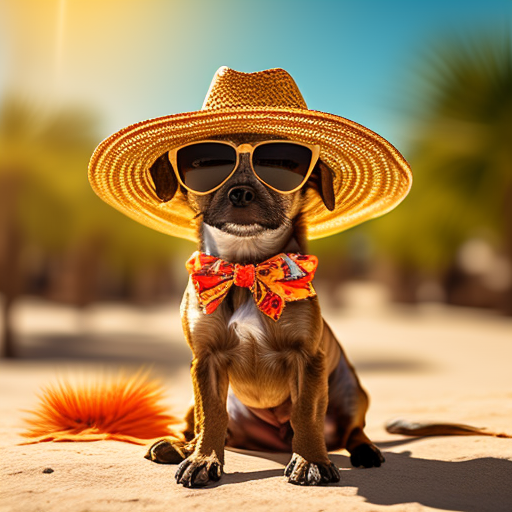

In [1]:
import torch
import PIL
import numpy as np
import gc
from tqdm.auto import tqdm
from diffusers import PixArtAlphaPipeline
from IPython.display import display

def pixart_text_to_image(pipe, prompt, negative_prompt="", seed=None, steps=20, guidance_scale=4.5, height=512, width=512):
    # מוודאים שהתקן הוא ה-GPU הראשי
    device = pipe._execution_device if hasattr(pipe, "_execution_device") else torch.device("cuda" if torch.cuda.is_available() else "cpu")
    dtype = torch.float16
    
    if seed is not None:
        generator = torch.Generator(device=device).manual_seed(seed)
    else:
        generator = torch.Generator(device=device)

    # 1. Embed text using PixArt's built-in encoder (T5)
    prompt_embeds, prompt_attention_mask, negative_prompt_embeds, negative_prompt_attention_mask = pipe.encode_prompt(
        prompt, 
        device=device,
        negative_prompt=negative_prompt,
        do_classifier_free_guidance=True
    )
    
    prompt_embeds = torch.cat([negative_prompt_embeds, prompt_embeds], dim=0)
    prompt_attention_mask = torch.cat([negative_prompt_attention_mask, prompt_attention_mask], dim=0)

    # 2. Initialize pure noise in the latent space (מוודאים device=device)
    pipe.scheduler.set_timesteps(steps)
    latents = torch.randn(
        (1, 4, height // 8, width // 8), 
        generator=generator, 
        device=device, 
        dtype=dtype
    )
    latents = latents * pipe.scheduler.init_noise_sigma

    resolution = torch.tensor([height, width], dtype=dtype, device=device).repeat(2, 1)
    aspect_ratio = torch.tensor([float(height / width)], dtype=dtype, device=device).repeat(2, 1)
    added_cond_kwargs = {"resolution": resolution, "aspect_ratio": aspect_ratio}
    
    # 3. Main Denoising Loop
    print("Running PixArt DiT Denoising Loop...")
    for i, t in enumerate(tqdm(pipe.scheduler.timesteps)):
        
        latent_model_input = torch.cat([latents] * 2)
        
        # מוודאים שגם ה-scheduler וגם ה-t נמצאים באותו מתחם
        t = t.to(device)
        latent_model_input = pipe.scheduler.scale_model_input(latent_model_input, t)

        t_val = t.item() if isinstance(t, torch.Tensor) else t
        t_batch = torch.tensor([t_val, t_val], device=device)

        with torch.no_grad():
            noise_pred = pipe.transformer(
                latent_model_input,
                encoder_hidden_states=prompt_embeds,
                encoder_attention_mask=prompt_attention_mask,
                timestep=t_batch,
                added_cond_kwargs=added_cond_kwargs,
                return_dict=False,
            )[0]

        if noise_pred.shape[1] == 8:
            noise_pred, _ = noise_pred.chunk(2, dim=1)

        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        # מוודאים שכל הפלט חוזר ל-device הנכון
        latents = pipe.scheduler.step(noise_pred, t, latents).prev_sample
        latents = latents.to(device)
    
    # 4. Final decode from latent space to image space
    with torch.no_grad():
        latents = (1 / pipe.vae.config.scaling_factor) * latents
        vae_dtype = pipe.vae.dtype
        image = pipe.vae.decode(latents.to(vae_dtype)).sample

    # 5. Format to PIL Image
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

# --- קוד ההפעלה ---

# מנקים שאריות זיכרון ליתר ביטחון
torch.cuda.empty_cache()
gc.collect()

model_id = "PixArt-alpha/PixArt-XL-2-512x512"

print("Loading PixArt pipeline...")
pipe = PixArtAlphaPipeline.from_pretrained(
    model_id, 
    torch_dtype=torch.float16,
    use_safetensors=True
)

# מעבירים לניהול זיכרון חכם
pipe.enable_model_cpu_offload()

# הרצה!
prompt = "A small dog, wearing sun glasses and mexican hat"
image = pixart_text_to_image(pipe, prompt, seed=42, steps=20, guidance_scale=4.5)

display(image)